# PokéChallenge 2026 — who wins a Gen 2 OU battle?

Given the first 30 turns of a Pokémon Showdown Gen 2 OU battle, predict whether player 1 wins.
This notebook rebuilds the **three submissions** of the challenge from the project's repository
and reports their **experimental evaluation**.

| # | submission | what it is |
|---|---|---|
| 1 | `compact_v5` | 18 hand-picked features, four boosters started from a logistic regression's log-odds (`ensemble_from_lr`, tuned members) |
| 2 | `v11` | 819 features, three stacked boosters and a spline logistic regression with a team effect, blended (`v11_blend`) |
| 3 | `blend` | the 50/50 average of the logits of the two |

The notebook does not copy the code: it clones the repository, creates the pinned Python
environment and calls the repository's command line (`python main.py …`) and the scripts of
`docs/evaluation/`. Everything is fitted on `train.jsonl` only; the test battles are only
predicted.

**Contents:** 1. setup · 2. data, Pokédex and knockout detectors · 3. the three submissions ·
4. experimental evaluation (metrics, ROC curves, accuracy by turn, convergence of the log loss,
feature mapping).

## 1. Setup

`RUN_EVALUATION` chooses where the evaluation tables of section 4 come from:

* `False` (default): the tables stored in the repository (`docs/evaluation/data/`), produced by
  exactly the commands shown in section 4 — the notebook then runs in about one hour;
* `True`: every experiment is run again here (several hours: v11 refits 819 features in every
  fold and at every point of the learning curve).

The three submissions of section 3 are always trained and predicted here.

In [ ]:
REPOSITORY = "https://github.com/CiottoloMaggico/pokechallenge-fall-2026.git"
REVISION = "main"
RUN_EVALUATION = False
SEED = 33  # the fold assignment of the evaluation (stratified grouped 5-fold)
TURNS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28]  # and 30, the whole battle
CURVE_STEP = 250  # battles between two points of the learning curve

In [ ]:
import os
import subprocess
import sys
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    ROOT = Path("/kaggle/temp/pokechallenge")  # the clone (not saved with the notebook)
    WORK = Path("/kaggle/working")  # submissions and tables (saved)
    if not ROOT.exists():
        ROOT.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["git", "clone", "--branch", REVISION, REPOSITORY, str(ROOT)],
            check=True,
            env={**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"},
        )
    PYTHON = Path("/kaggle/temp/env/bin/python")
else:  # a local checkout: this file is docs/notebook/pokechallenge.ipynb
    ROOT = Path.cwd().resolve().parents[1]
    WORK = ROOT / "results" / "notebook"
    PYTHON = ROOT / ".env" / "bin" / "python"
WORK.mkdir(parents=True, exist_ok=True)


def run(*command, quiet=False):
    """Run a command from the repository's root and stream its output."""
    command = [str(part) for part in command]
    print("$", " ".join(command), flush=True)
    process = subprocess.Popen(
        command, cwd=ROOT, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT
    )
    lines = []
    for line in process.stdout:
        lines.append(line)
        if not quiet and "Warning" not in line and "warn" not in line:
            print(line, end="", flush=True)
    if process.wait() != 0:
        raise RuntimeError("".join(lines[-30:]))


def main(*arguments, **options):
    """``python main.py …`` with the project's interpreter."""
    run(PYTHON, "main.py", *arguments, **options)


print(
    subprocess.run(
        ["git", "log", "-1", "--format=%h %s"], cwd=ROOT, text=True, capture_output=True
    ).stdout.strip()
)

The results depend on the library versions (the exact v11 reproduction in particular), so the
project runs in its own environment — Python 3.14 with the versions pinned in
`requirements.txt` — whatever the notebook's kernel is. The kernel itself only reads tables and
draws figures.

In [ ]:
if not PYTHON.exists():
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv"], check=True)
    run(sys.executable, "-m", "uv", "venv", "--python", "3.14", PYTHON.parents[1], quiet=True)
    run(
        sys.executable,
        "-m",
        "uv",
        "pip",
        "install",
        "--python",
        PYTHON,
        "-r",
        "requirements.txt",
        quiet=True,
    )
run(
    PYTHON,
    "-c",
    "import sys, sklearn, lightgbm, xgboost, catboost; print(sys.version.split()[0], "
    "'| scikit-learn', sklearn.__version__, '| lightgbm', lightgbm.__version__, '| xgboost', "
    "xgboost.__version__, '| catboost', catboost.__version__)",
)

## 2. Data, Pokédex and knockout detectors

The competition files are read from the Kaggle input folder (or from `input/` in a local
checkout). Three things are built once from the **training file only**:

* the **Pokédex** (base stats and types of every species seen in the training records);
* the **knockout detector of `compact_v5`** (`v3`): the timeline does not show every faint of
  player 2's Pokémon, so a gradient boosting trained on player 1's switches — where the faint
  *is* recorded — estimates the hidden ones and repairs the replay before any feature is
  computed. It never sees `player_won`;
* the **knockout detector of `v11`**, the same idea with v11's own description of a switch.

In [ ]:
def data_file(name):
    """The competition file ``name``: under /kaggle/input, else the repository's input/."""
    found = sorted(Path("/kaggle/input").rglob(name)) if ON_KAGGLE else []
    path = found[0] if found else ROOT / "input" / name
    if path.stat().st_size < 10_000:  # a Git LFS pointer, not the data
        raise FileNotFoundError(f"{path}: add the competition data to the notebook")
    return path


TRAIN, TEST = data_file("train.jsonl"), data_file("test.jsonl")
POKEDEX = ROOT / "results" / "cache" / "species.json"
V3 = ROOT / "results" / "addons" / "knockouts" / "v3"
V11 = ROOT / "results" / "addons" / "knockouts_v11" / "v1"
REPAIR_V3, REPAIR_V11 = f"model={V3}", f"v11={V11}"
PARAMS = sorted((ROOT / "assets" / "params").glob("compact_v5__*_lr.json"))

if not POKEDEX.exists():
    run(PYTHON, "-m", "domain", "build-pokedex", TRAIN, "--out", POKEDEX)
if not V3.exists():
    main(
        "--pokedex",
        POKEDEX,
        "detector",
        "train",
        "--train",
        TRAIN,
        "--version",
        "v3",
        "--seeds",
        42,
        1,
        2,
    )
if not V11.exists():
    main(
        "--pokedex",
        POKEDEX,
        "detector",
        "train-v11",
        "--train",
        TRAIN,
        "--version",
        "v1",
        "--seeds",
        42,
        1,
        2,
    )
print("train:", TRAIN, "\ntest: ", TEST)

## 3. The three submissions

Each model is fitted on the 10,000 training battles and predicts the 5,000 test battles.

* **`compact_v5`** — `ensemble_from_lr` with the hyper-parameters found by Optuna
  (`assets/params/`), on the replay repaired by detector `v3`.
* **`v11`** — the `blend_v11` model of the course repository rebuilt on this repository's
  constructs (`v11_blend`), on the replay repaired by its own detector.
* **`blend`** — `expit(0.5 · logit(p_compact_v5) + 0.5 · logit(p_v11))`
  (`docs/evaluation/blend.py`).

In [ ]:
RUNS, SUBMISSIONS = WORK / "runs", WORK / "submissions"
MODELS = {  # name: (feature set, model, repair, extra arguments of train)
    "compact_v5": ("compact_v5", "ensemble_from_lr", REPAIR_V3, ["--params", *PARAMS]),
    "v11": ("v11", "v11_blend", REPAIR_V11, []),
}
for name, (features, model, repair, extra) in MODELS.items():
    run_name = f"{features}__{model}" + ("-tuned" if extra else "")
    if not (RUNS / run_name).exists():
        main(
            "--pokedex",
            POKEDEX,
            "train",
            "--train",
            TRAIN,
            "--features",
            features,
            "--models",
            model,
            "--repair",
            repair,
            *extra,
            "--out",
            RUNS,
        )
    main(
        "--pokedex",
        POKEDEX,
        "predict",
        "--run",
        RUNS / run_name,
        "--test",
        TEST,
        "--repair",
        repair,
        "--out",
        SUBMISSIONS / f"submission_{name}.csv",
        "--proba",
        SUBMISSIONS / f"proba_{name}.csv",
    )
run(
    PYTHON,
    "docs/evaluation/blend.py",
    SUBMISSIONS / "proba_compact_v5.csv",
    SUBMISSIONS / "proba_v11.csv",
    "--out",
    SUBMISSIONS / "submission_blend.csv",
    "--proba",
    SUBMISSIONS / "proba_blend.csv",
)

The three files are `submission_compact_v5.csv`, `submission_v11.csv` and `submission_blend.csv`.
The table below shows how much they differ on the test battles: predicted share of player-1
wins and number of battles on which two submissions disagree.

In [ ]:
import pandas as pd

sys.path.insert(0, str(ROOT / "docs" / "evaluation"))
import plots

plots.apple_style()
NAMES = ["compact_v5", "v11", "blend"]
labels = pd.DataFrame(
    {name: pd.read_csv(SUBMISSIONS / f"submission_{name}.csv")["player_won"] for name in NAMES}
)
overview = pd.DataFrame(
    {
        "Submission": [plots.MODELS[name] for name in NAMES],
        "Predicted P1 wins": [f"{labels[name].mean():.1%}" for name in NAMES],
    }
)
for other in NAMES:
    overview[f"≠ {plots.MODELS[other]}"] = [
        int((labels[name] != labels[other]).sum()) for name in NAMES
    ]
plots.table_style(overview)

Submission,Predicted P1 wins,≠ compact_v5,≠ v11,≠ blend 50/50
compact_v5,51.2%,0,559,273
v11,51.1%,559,0,286
blend 50/50,51.1%,273,286,0


## 4. Experimental evaluation

**Protocol.** Every number is a cross-validation on the 10,000 training battles: stratified
5-fold, grouped so that duplicated battles stay in the same fold, with one fold assignment
(seed 33) shared by the three models. Everything that learns — features included — is refitted
inside each training fold; features that read the labels give their own training rows out of
fold. The two knockout detectors are fitted once on the training file, as above (they never
read the labels). The blend is computed from the out-of-fold probabilities of the two models.
Differences between models are tested on the same folds with the corrected repeated k-fold
t-test (Nadeau & Bengio), which does not treat overlapping training sets as independent.

The hyper-parameters of `compact_v5` were tuned on the same training battles (on other folds,
seed 2027), so its numbers keep a small residual optimism.

In [ ]:
EVALUATION = WORK / "evaluation"
DATA = EVALUATION / "data" if RUN_EVALUATION else ROOT / "docs" / "evaluation" / "data"
SUMMARIZE = [PYTHON, "docs/evaluation/summarize.py"]

if RUN_EVALUATION:
    for name, (features, model, repair, extra) in MODELS.items():
        main(
            "--pokedex",
            POKEDEX,
            "evaluate",
            "--train",
            TRAIN,
            "--features",
            features,
            "--models",
            model,
            "--repair",
            repair,
            *extra,
            "--seeds",
            SEED,
            "--out",
            EVALUATION / name,
            quiet=True,
        )
    run(
        *SUMMARIZE,
        "models",
        "--compact",
        EVALUATION / "compact_v5",
        "--v11",
        EVALUATION / "v11",
        "--out",
        DATA,
    )


def table(name):
    return pd.read_csv(DATA / f"{name}.csv")

### 4.1 Performance of the three models

Accuracy and ROC AUC: higher is better. Log loss and Brier score: lower is better. "± fold" is
the standard deviation of the accuracy over the five folds.

In [ ]:
plots.metrics_table(table("metrics"))

Model,Accuracy,± fold,Log loss,ROC AUC,Brier,Folds
compact_v5,0.7184,0.0105,0.5407,0.7982,0.1831,5
v11,0.7175,0.0047,0.5417,0.7979,0.1833,5
blend 50/50,0.7232,0.0081,0.5355,0.8034,0.1809,5


Paired differences on the same folds (first model minus second) with the p-value of the
corrected t-test:

In [ ]:
plots.paired_table(table("paired"))

Difference,Δ accuracy,Δ log loss,Δ ROC AUC,Δ Brier
compact_v5 − v11,+0.0009 (p 0.853),-0.0009 (p 0.665),+0.0003 (p 0.901),-0.0002 (p 0.812)
compact_v5 − blend 50/50,-0.0048 (p 0.410),+0.0052 (p 0.006),-0.0053 (p 0.011),+0.0022 (p 0.011)
v11 − blend 50/50,-0.0057 (p 0.099),+0.0061 (p 0.005),-0.0056 (p 0.006),+0.0025 (p 0.007)


**Reading.** `compact_v5` and `v11` are indistinguishable from each other on every metric,
although one uses 18 columns and the other 819: the fold-to-fold spread of the accuracy is
several times the difference between them. They are not the same model, though — they disagree
on several hundred test battles (section 3) — and averaging them is the only step that moves the
probabilistic metrics beyond noise: log loss, ROC AUC and Brier score of the blend are
significantly better than those of either model, while the gain in accuracy stays within the
fold-to-fold spread.

### 4.2 ROC curves

One curve per model from its 10,000 out-of-fold probabilities (each battle is predicted by the
model that did not train on it). The inset zooms on the knee of the curves.

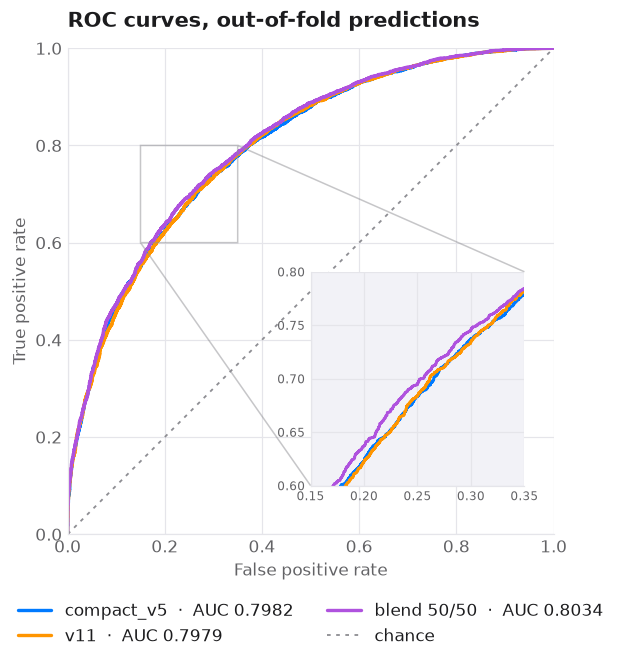

In [ ]:
FIGURES = WORK / "figures"
plots.plot_roc(table("oof"), table("metrics"), FIGURES);

### 4.3 Accuracy by last turn seen

How much of the outcome is already decided after *N* turns? Every battle of the training file
is cut to its first *N* turns (`docs/evaluation/truncate.py`), and the whole `compact_v5`
pipeline — knockout repair, features, model — is cross-validated on the cut battles, on the
same folds.

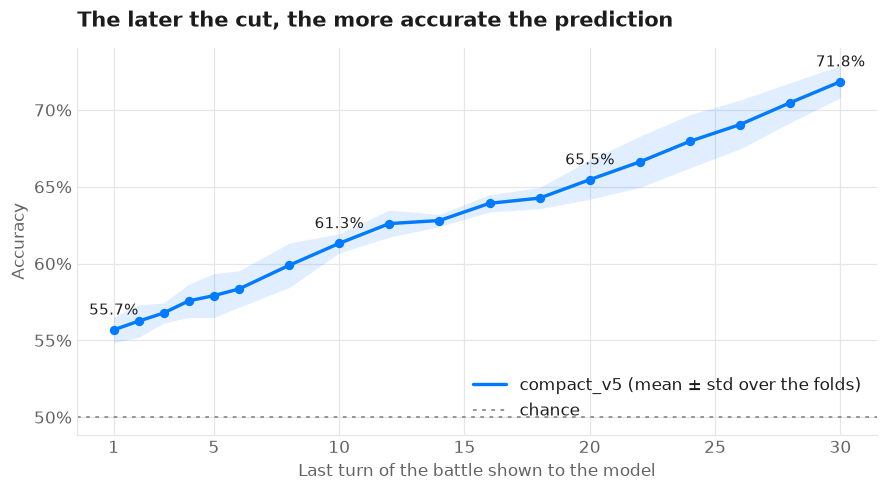

In [ ]:
if RUN_EVALUATION:
    for turn in TURNS:
        cut = EVALUATION / "turns" / f"train_t{turn}.jsonl"
        run(PYTHON, "docs/evaluation/truncate.py", TRAIN, "--turn", turn, "--out", cut)
        features, model, repair, extra = MODELS["compact_v5"]
        main(
            "--pokedex",
            POKEDEX,
            "evaluate",
            "--train",
            cut,
            "--features",
            features,
            "--models",
            model,
            "--repair",
            repair,
            *extra,
            "--seeds",
            SEED,
            "--out",
            EVALUATION / "turns" / f"t{turn}",
            quiet=True,
        )
        cut.unlink()
    run(
        *SUMMARIZE,
        "turns",
        "--runs",
        EVALUATION / "turns",
        "--full",
        EVALUATION / "compact_v5",
        "--seed",
        SEED,
        "--out",
        DATA,
    )

plots.plot_accuracy_by_turn(table("accuracy_by_turn"), FIGURES);

In [ ]:
by_turn = table("accuracy_by_turn").groupby("turn")[["accuracy", "log_loss", "roc_auc"]].mean()
shown = by_turn[by_turn.index.isin([1, 5, 10, 15, 20, 25, 30])]
plots.table_style(shown.reset_index()).format(precision=4)

turn,accuracy,log_loss,roc_auc
1,0.5568,0.6794,0.5870
5,0.5791,0.6706,0.6167
10,0.6131,0.6527,0.6570
20,0.6546,0.6127,0.7186
30,0.7184,0.5407,0.7982


**Reading.** After the first turn — the two leads and player 1's team — the model is right
55.7 % of the time. Every further turn adds about half a point of accuracy, with no plateau:
61.3 % after 10 turns, 65.5 % after 20, 71.8 % with all 30, while the ROC AUC goes from 0.59 to
0.80. The battle is still being decided when the recording stops, which also bounds what any
model can reach from 30 turns.

### 4.4 Convergence of the log loss

How do the models improve as the training battles grow, and would more battles help? For one
validation fold (2,000 battles, fold 0 of the same fold assignment) each model is refitted from
scratch — features included — on the first *n* of the other 8,000 battles, in a fixed random
order, with a point every 250 battles (`docs/evaluation/learning_curve.py`). The subsets are
nested, so a curve only changes because battles are added.

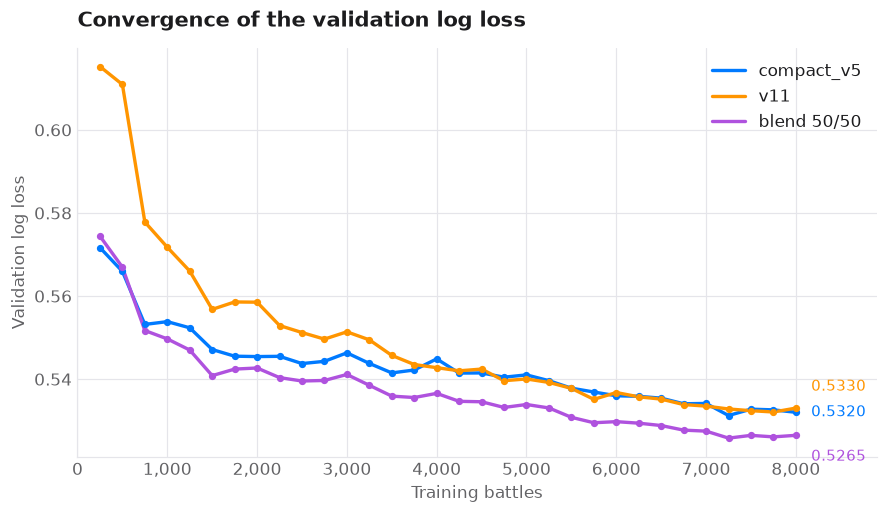

In [ ]:
if RUN_EVALUATION:
    sizes = list(range(CURVE_STEP, 8000, CURVE_STEP))
    for name, (features, model, repair, extra) in MODELS.items():
        run(
            PYTHON,
            "docs/evaluation/learning_curve.py",
            "--train",
            TRAIN,
            "--pokedex",
            POKEDEX,
            "--features",
            features,
            "--models",
            model,
            "--repair",
            repair,
            *extra,
            "--seed",
            SEED,
            "--folds",
            0,
            "--sizes",
            *sizes,
            "--out",
            EVALUATION / f"curve_{name}.csv",
        )
    run(
        *SUMMARIZE,
        "curve",
        "--compact",
        EVALUATION / "curve_compact_v5.csv",
        "--v11",
        EVALUATION / "curve_v11.csv",
        "--out",
        DATA,
    )

plots.plot_loss_convergence(table("loss_curve"), FIGURES);

The same experiment with the log loss on the training battles themselves (dashed): the distance
between the two lines is the generalisation gap.

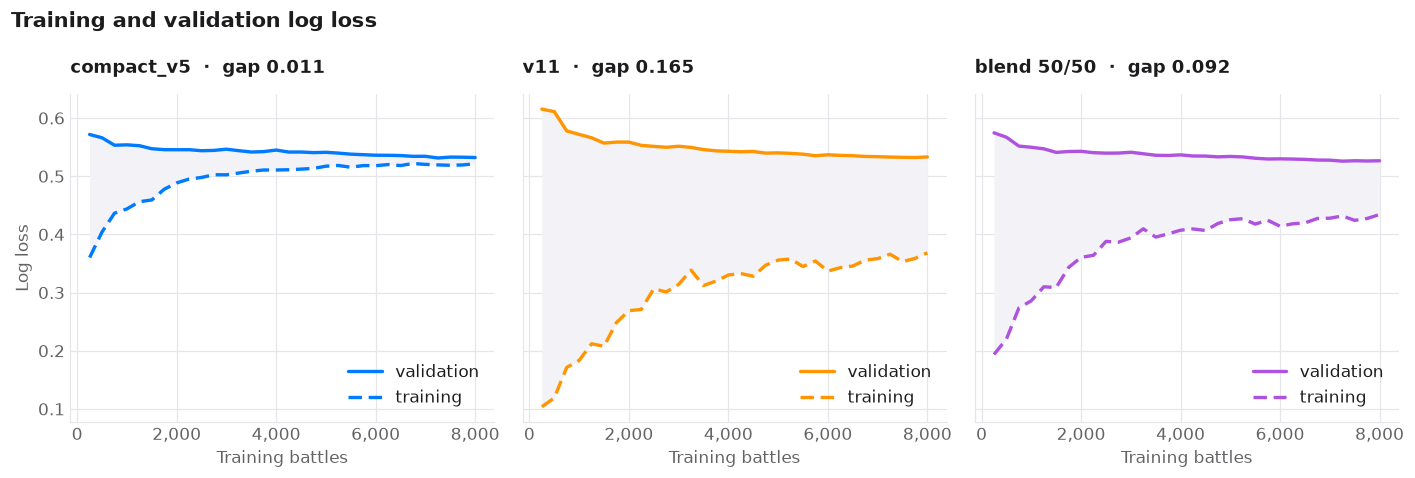

In [ ]:
plots.plot_generalization_gap(table("loss_curve"), FIGURES);

**Reading.**

* The validation loss of every model falls quickly over the first 1,500 battles and then more
  and more slowly; it is still decreasing at 8,000 (the last 2,000 battles lower it by about
  0.004 for both models), so more battles would still help, a little.
* `v11` needs more data than `compact_v5`: with 250 battles it is far worse (0.615 against
  0.572), it catches up at about 4,000 battles and the two are indistinguishable from there on.
  The 50/50 blend is the lowest curve from 750 battles on, by about 0.006 at the end.
* The training loss tells the two models apart. `compact_v5`, with 18 features, fits its
  training battles only a little better than new ones (gap 0.011 at 8,000 battles); `v11`,
  with 819 features and stacked boosters, fits them far better (gap 0.165) and the gap closes
  only slowly. The same validation loss is reached with very different amounts of memorisation.

These curves come from a single validation fold, so wiggles of a few thousandths are noise, and
their last points are not the five-fold means of section 4.1.

### 4.5 From the feature groups of `v11` to the features of `compact_v5`

`v11` describes a battle with 819 columns in 15 groups; `compact_v5` with 18 columns chosen
one at a time with the corrected t-test. The table lists every v11 group, what it holds, and the
`compact_v5` features that measure the same quantity (with the closest v11 columns). Groups in
grey have no counterpart in `compact_v5`.

In [ ]:
plots.mapping_table(table("feature_mapping"))

v11 group,prefix,columns,what the group holds,compact_v5 features,closest v11 columns
static,s_,40,"P1's team stats, levels, items and weaknesses; P2's lead; the lead matchup",—,—
state,f_,52,"faints (hidden P2 ones from the detector), HP left, status counts of both teams","smat_hp, p2_fainted, p2_hidden_ko_unsure, material_healthy","f_p1_hp_sum, f_p2_hp_sum_opt / _hard; f_p2_fainted, f_p2_fainted_hard; f_p2_pf_uncertain; f_p*_n_slp / par / tox / psn / brn / frz"
trajectory,t_,25,"faint and HP differences at turns 5–25, their mean, range and slope",hpw_spd_t20 (a turn-20 snapshot),"t_hd_20, t_fd_20 (same idea, other quantity)"
active,a_,81,"the two active Pokémon: HP, status, boosts, effects, speed order, damage and turns-to-KO both ways","bst_sum, eff_substitute","a_a1 / a2_boost_pos, _boost_neg; a_a1 / a2_e_substitute"
events,e_,126,"what each player did: move classes, effectiveness, switches, damage dealt, hazards, weather","spikes_on_field, switch_excess_all, b_stat_diff",e_*_spikes_on_opp; e_*_switches; e_*_status_moves
matchup,m_,13,"matchup matrix of the Pokémon still alive: coverage, sweepers, walls, one-hit KOs",sim_seen_left (in part),m_win_mean
win conditions,w_,25,"spinners, set-up, phazers, healers, boomers, sleepers, Spikes, trapping",spikes_on_field,"w_spikes_on_p1, w_spikes_on_p2, w_spikes_adv"
sleep,x_,9,"longest current sleep, Rest and induced sleepers of each player",—,—
bags,"bs_, bh_, bm_",≈360,"one column per species (present, HP left) and per revealed move, over the training vocabulary; the members replace them with one stacked logit","tr_p1, tr_p2 (in part)",bs_* (team composition)
team keys,k_,27,"ids of teams, sub-teams and species; the members replace them with the team effect tm* (9 columns)","tr_p1, tr_p2, te_pair_mean","tm, tm_raw1, tm_raw2; tm_pair"


**Reading.** Every one of the 18 `compact_v5` features has a close relative in `v11`: the two
models were built independently but converge on the same quantities — material left (HP,
knockouts, status), hazards, boosts, switching behaviour, a simulation of the rest of the
battle and the strength of the teams. What `v11` adds — static team descriptors, trajectories,
sleep, the learned forecast, the bags of species and moves — does not improve the
cross-validated metrics (section 4.1), but it makes the two models err on different battles,
which is what the blend exploits.

## 5. Conclusions

* The three submissions are rebuilt above from the training file alone, with the repository's
  command line and pinned library versions.
* `compact_v5` (18 features) and `v11` (819 features) reach the same accuracy, log loss and
  ROC AUC within noise; their 50/50 blend is significantly better calibrated and ranked than
  either.
* The outcome becomes predictable gradually with the turns, about half a point of accuracy per
  turn: from 55.7 % after the first turn to 71.8 % with all 30.
* The validation log loss of every model is still decreasing at 8,000 battles, slowly: more
  battles would help a little. The large model needs about 4,000 battles to match the small
  one and memorises its training battles far more.